# Which text fields improve quality ranking?

Adding the question body improves mean OOF Spearman by 0.0735–0.0745; adding the answer improves it by another 0.0306–0.0318 across three matched grouped split plans. These controlled text-view effects are larger than the observed split-plan spread. This is a TF-IDF/Ridge result, not a transformer ablation.

This executed analysis reads only committed aggregate results. Training data, row-level OOF predictions and model weights remain private.

The aggregate gain hides a tradeoff: adding the answer improves answer-target means while slightly reducing question-target means in all three plans. The target-group table keeps both effects visible.

## Hypothesis and controlled comparison

A title conveys topic and wording but omits detail and answer relevance. Keep two slots and the same model: `(title, title)` → `(title + body, title)` → `(title + body, title + answer)`. Each step adds one field to one slot. Vocabulary and IDF are fitted only on training views; the vocabulary cap, Ridge regularization, solver and budgets remain fixed.

[Detailed method and rerun command](../docs/modeling-study.md).

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
study = json.loads((ROOT / "docs/modeling-study.json").read_text())
assert study["status"] == "completed"
assert hashlib.sha256((ROOT / "scripts/ablation_study.py").read_bytes()).hexdigest() == study["script_sha256"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Source: docs/modeling-study.json; input and assignment hashes retained in receipt")
print("Observed total runtime (s):", round(study["elapsed_seconds"], 1))


Source: docs/modeling-study.json; input and assignment hashes retained in receipt
Observed total runtime (s): 118.5


## Retain every matched result

Seeds 42, 43 and 44 change the grouped category-stratified partition. Every variant uses the same partition within a seed; repeated question bodies never cross fit/validation. Ridge is deterministic here: this measures split sensitivity, not invented model-seed randomness.

In [2]:
labels = {"title_only": "Title", "title_body": "Title + body", "title_body_answer": "Title + body + answer"}
rows = pd.DataFrame([{"Split seed": run["split_seed"], "Input": labels[run["variant"]], "Mean Spearman": run["pooled_oof"]["mean_spearman_30_zero_fallback"], "Question targets": run["pooled_oof"]["question_mean_spearman"], "Answer targets": run["pooled_oof"]["answer_mean_spearman"]} for run in study["runs"]])
display(rows.round(6))


,Split seed,Input,Mean Spearman,Question targets,Answer targets
0,42,Title,0.219740,0.256639,0.133641
1,42,Title + body,0.294272,0.343273,0.179935
2,42,Title + body + answer,0.326114,0.341119,0.291101
3,43,Title,0.220702,0.256604,0.136930
4,43,Title + body,0.295146,0.341646,0.186643
5,43,Title + body + answer,0.325728,0.340531,0.291188
6,44,Title,0.219961,0.256280,0.135216
7,44,Title + body,0.293442,0.340635,0.183325
8,44,Title + body + answer,0.325071,0.339167,0.292179


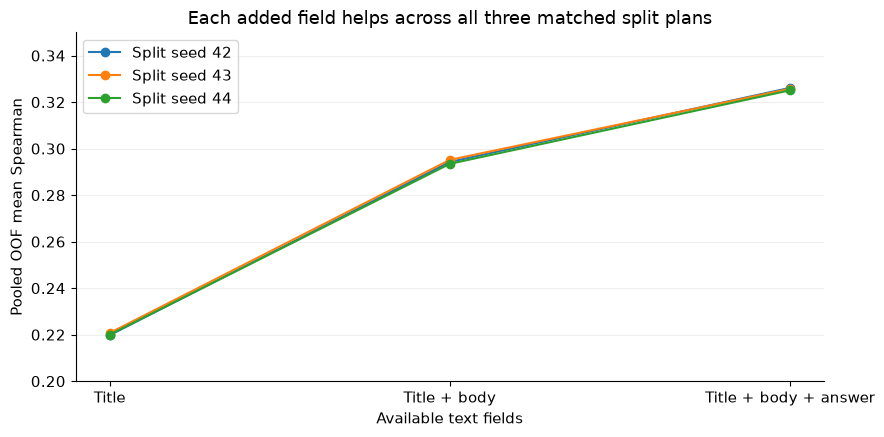

In [3]:
fig, ax = plt.subplots()
for seed, group in rows.groupby("Split seed", sort=True):
    ordered = group.set_index("Input").loc[list(labels.values())]
    ax.plot(range(3), ordered["Mean Spearman"], marker="o", label=f"Split seed {seed}")
ax.set(xticks=range(3), xticklabels=list(labels.values()), ylabel="Pooled OOF mean Spearman", xlabel="Available text fields", title="Each added field helps across all three matched split plans")
ax.set_ylim(0.20, 0.35)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


## Compare changes within each seed

Subtract the simpler variant from the richer variant within the same split and training budget. Pairing prevents a changed partition from explaining the component effect.

,add_body_delta,add_answer_delta
split_seed,,
42,0.074532,0.031842
43,0.074444,0.030582
44,0.073481,0.031629


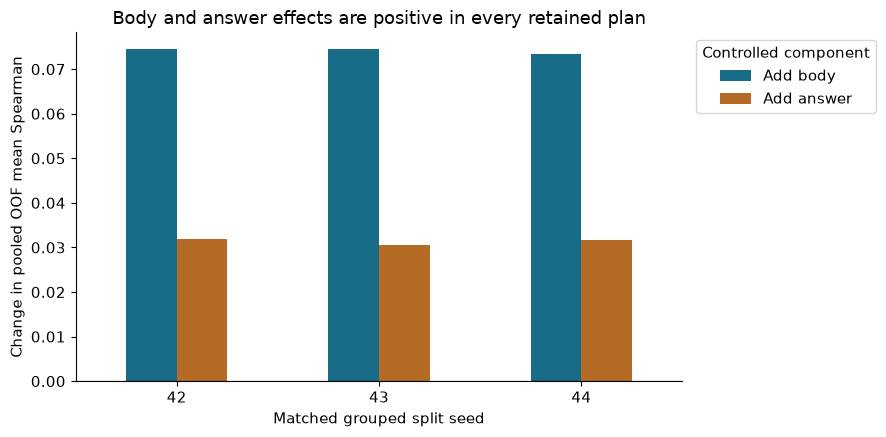

In [4]:
paired = pd.DataFrame(study["paired_deltas"]).set_index("split_seed")
display(paired.round(6))
fig, ax = plt.subplots()
paired.rename(columns={"add_body_delta": "Add body", "add_answer_delta": "Add answer"}).plot.bar(ax=ax, color=["#176b87", "#b46b26"], rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Matched grouped split seed", ylabel="Change in pooled OOF mean Spearman", title="Body and answer effects are positive in every retained plan")
ax.legend(title="Controlled component", loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()
assert (paired > 0).all().all()


## Interpretation and limits

Three split plans are descriptive evidence, not a confidence interval. This study supports retaining body and answer views for this lightweight recipe. It does not explain transformer architecture effects or predict leaderboard rank. The original DeBERTa holdout remains a separate experiment.

The aggregate receipt retains per-fold metrics, exact configurations, source/input/assignment/output hashes and independent reload checks. [Study receipt](../docs/modeling-study.json) · [Main walkthrough](./01-question-quality.ipynb)

Answer-target means gain +0.1045–+0.1112, while question-target means decline −0.0022–−0.0011 when answer text is added. A target-specific representation is a plausible next hypothesis; this study does not establish its mechanism or benefit.